# **ИКБО-62-23 Чекалов А.В. 29.10.2026**

# **1. Учебный раздел по ecommerce.sqlite**

Выгружает пять таблиц из учебной базы SQLite в CSV-файлы. Крупная таблица читается порциями, чтобы не загружать все строки в память сразу; после выгрузки печатается количество строк по каждой таблице.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd

DB_PATH = Path("ecommerce.sqlite")
STAGING = Path("spark_input")
STAGING.mkdir(exist_ok=True)

TABLES = [
    "geolocation", "order_items", "products", "sellers",
    "product_category_name_translation"
]

with sqlite3.connect(DB_PATH) as con:
    for table in TABLES:
        out = STAGING / f"{table}.csv"
        first = True
        total = 0
        for chunk in pd.read_sql_query(
            f"SELECT * FROM {table}", con, chunksize=100_000
        ):
            chunk.to_csv(
                out, index=False,
                mode="w" if first else "a",
                header=first, encoding="utf-8"
            )
            total += len(chunk)
            first = False
        print(f"{table:40s} {total:>9d} rows")

geolocation                                1000163 rows
order_items                                 112650 rows
products                                     32951 rows
sellers                                       3095 rows
product_category_name_translation               71 rows


#### Таблица 2. Паспорт экспериментального стенда

| Параметр | Фактическое значение |
| :--- | :--- |
| ОС | Windows 10/11 |
| Python | 3.12.8 |
| Java | 17.0.12 |
| PySpark / Spark | 4.2.0 |
| Логических CPU | 12 |
| Оперативная память | 20 GB |
| spark.master | local[*] |
| spark.default.parallelism | 12 |
| spark.sql.shuffle.partitions | 8 |
| spark.sql.adaptive.enabled | false |

Настраивает окружение для Java и Hadoop, затем создаёт локальную сессию Spark с использованием всех доступных ядер. Фиксирует число разделов после перемешивания, отключает адаптивное выполнение запросов и автоматическое широковещательное соединение, печатает основные параметры и адрес интерфейса наблюдения.

In [2]:
import os
import sys

# Настройка Java (из вашего успешного опыта)
os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

# Настройка Hadoop (из вашей 3-й практики)
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"

# Настройка Python для PySpark
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Practice5_SparkExecution")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.autoBroadcastJoinThreshold", "-1")
    .config("spark.ui.port", "8088")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
print("Spark UI:", spark.sparkContext.uiWebUrl)

C:\Users\lesha\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Master: local[*]
Default parallelism: 12
Shuffle partitions: 8
AQE: false
Spark UI: http://DESKTOP-THINKBOOK69:8088


Читает CSV-файлы, определяет типы столбцов и сохраняет те же таблицы в формате Parquet. Затем заново читает Parquet-версии и печатает контрольное количество строк, чтобы убедиться, что подготовка данных прошла успешно.

In [3]:
PARQUET = Path("spark_input_parquet")
PARQUET.mkdir(exist_ok=True)

for name in TABLES:
    df = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(str(STAGING / f"{name}.csv"))
    )
    df.write.mode("overwrite").parquet(str(PARQUET / name))

geo = spark.read.parquet(str(PARQUET / "geolocation"))
items = spark.read.parquet(str(PARQUET / "order_items"))
products = spark.read.parquet(str(PARQUET / "products"))
sellers = spark.read.parquet(str(PARQUET / "sellers"))
translations = spark.read.parquet(
    str(PARQUET / "product_category_name_translation")
)

print(geo.count(), items.count(), products.count(), sellers.count())

1000163 112650 32951 3095


Помечает следующий запуск отдельной группой в интерфейсе Spark и выполняет простой подсчёт строк в таблице позиций заказов. Это базовая проверка, что задание действительно появляется в интерфейсе наблюдения.

In [4]:
sc = spark.sparkContext

sc.setJobGroup(
    "P5_BASELINE",
    "Практика 5: базовая проверка Spark UI", interruptOnCancel=True
)

_ = items.count()

Показывает ленивость вычислений: строит новый фрейм данных через выбор части столбцов, отбрасывание пустых значений и добавление вычисляемого столбца. При этом реальная обработка ещё не запускается; печатается только тип полученного объекта.

In [5]:
sc.setJobGroup("P5_LAZY", "Lazy evaluation")

geo_prepared = (
    geo
    .select(
        "geolocation_zip_code_prefix",
        "geolocation_state",
        "geolocation_lat",
        "geolocation_lng"
    )
    .filter(F.col("geolocation_state").isNotNull())
    .withColumn("abs_lat", F.abs(F.col("geolocation_lat")))
)

print(type(geo_prepared).__name__)

DataFrame


Выполняет подсчёт строк в подготовленном фрейме данных. Именно это действие заставляет Spark реально прочитать данные и выполнить всю цепочку преобразований; замеряется затраченное время.

In [6]:
from time import perf_counter

t0 = perf_counter()
n = geo_prepared.count()
elapsed = perf_counter() - t0

print("Rows:", n)
print(f"Elapsed: {elapsed:.3f} s")

Rows: 1000163
Elapsed: 0.621 s


Смотрит, на сколько входных разделов разбита крупная таблица геолокации, и сравнивает это с числом доступных вычислительных слотов. Затем считает, сколько строк попадает в каждый раздел, чтобы увидеть фактическую неравномерность.

In [7]:
print("Input partitions:", geo.rdd.getNumPartitions())
print("Default parallelism:", sc.defaultParallelism)

partition_sizes = (
    geo
    .select(F.spark_partition_id().alias("pid"))
    .groupBy("pid")
    .count()
    .orderBy("pid")
)
partition_sizes.show(100, truncate=False)

Input partitions: 12
Default parallelism: 12
+---+-----+
|pid|count|
+---+-----+
|0  |90353|
|1  |88373|
|2  |88104|
|3  |87668|
|4  |86154|
|5  |88355|
|6  |87983|
|7  |86853|
|8  |86841|
|9  |91182|
|10 |92908|
|11 |25389|
+---+-----+



Группирует таблицу геолокации по штату и показывает пять штатов с наибольшим числом строк. Это демонстрирует естественный перекос данных: один штат занимает заметно большую долю, чем остальные.

In [8]:
state_counts = (
    geo
    .groupBy("geolocation_state")
    .count()
    .orderBy(F.desc("count"))
)
state_counts.show(5, truncate=False)

+-----------------+------+
|geolocation_state|count |
+-----------------+------+
|SP               |404268|
|MG               |126336|
|RJ               |121169|
|RS               |61851 |
|PR               |57859 |
+-----------------+------+
only showing top 5 rows


#### Таблица 3. Пять наиболее представленных штатов в geolocation

| state | Строк | Доля, % |
| :--- | :--- | :--- |
| SP | 404268 | 40.42 |
| MG | 126336 | 12.63 |
| RJ | 121169 | 12.11 |
| RS | 61851 | 6.18 |
| PR | 57859 | 5.78 |

Создаёт намеренно перекошенное разбиение по штату, а затем двумя разными способами уменьшает число разделов до четырёх. Один вариант перераспределяет данные заново, другой только объединяет соседние разделы; печатается итоговое число разделов.

In [9]:
skewed16 = geo.repartition(16, "geolocation_state")
repart4 = skewed16.repartition(4)
coal4 = skewed16.coalesce(4)

print("skewed16:", skewed16.rdd.getNumPartitions())
print("repart4:", repart4.rdd.getNumPartitions())
print("coal4:", coal4.rdd.getNumPartitions())

skewed16: 16
repart4: 4
coal4: 4


Печатает физические планы для двух вариантов уменьшения числа разделов. В одном плане видно полное перераспределение данных, во втором — только объединение разделов без такого перемешивания; это объясняет разницу в стоимости.

In [10]:
print("=== repartition(4) ===")
repart4.explain("formatted")

print("=== coalesce(4) ===")
coal4.explain("formatted")

=== repartition(4) ===
== Physical Plan ==
Exchange (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_id:int,geolocation_zip_code_prefix:int,geolocation_lat:double,geolocation_lng:double,geolocation_city:string,geolocation_state:string>

(2) ColumnarToRow [codegen id : 1]
Input [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]

(3) Exchange
Input [6]: [geolocation_id#141, geolocation_zip_code_prefix#142, geolocation_lat#143, geolocation_lng#144, geolocation_city#145, geolocation_state#146]
Arguments: RoundRobinPartitioning(4), REPARTITION_BY_NUM, [plan_id=466]


=== coalesce(4) ===
== Physical P

Считает распределение строк по разделам для двух предыдущих вариантов. Сравнение показывает, что полное перераспределение выравнивает размеры разделов, а простое объединение сохраняет исходный перекос.

In [11]:
def partition_profile(df):
    return (
        df
        .select(F.spark_partition_id().alias("pid"))
        .groupBy("pid")
        .count()
        .orderBy("pid")
    )

print("repartition(4)")
partition_profile(repart4).show()

print("coalesce(4)")
partition_profile(coal4).show()

repartition(4)
+---+------+
|pid| count|
+---+------+
|  0|250040|
|  1|250041|
|  2|250041|
|  3|250041|
+---+------+

coalesce(4)
+---+------+
|pid| count|
+---+------+
|  0|195064|
|  1|626485|
|  2| 90152|
|  3| 88462|
+---+------+



#### Таблица 4. Экспериментальная таблица распределения partitions

| Вариант | min rows | max rows | mean rows | Комментарий |
| :--- | :--- | :--- | :--- | :--- |
| repartition(4) | 250040 | 250041 | 250040.75 | Данные распределены равномерно благодаря полному перемешиванию (RoundRobinPartitioning). |
| coalesce(4) | 88462 | 626485 | 250040.75 | Данные распределены крайне неравномерно, так как coalesce просто объединяет соседние партиции без перемешивания, сохраняя исходный перекос. |

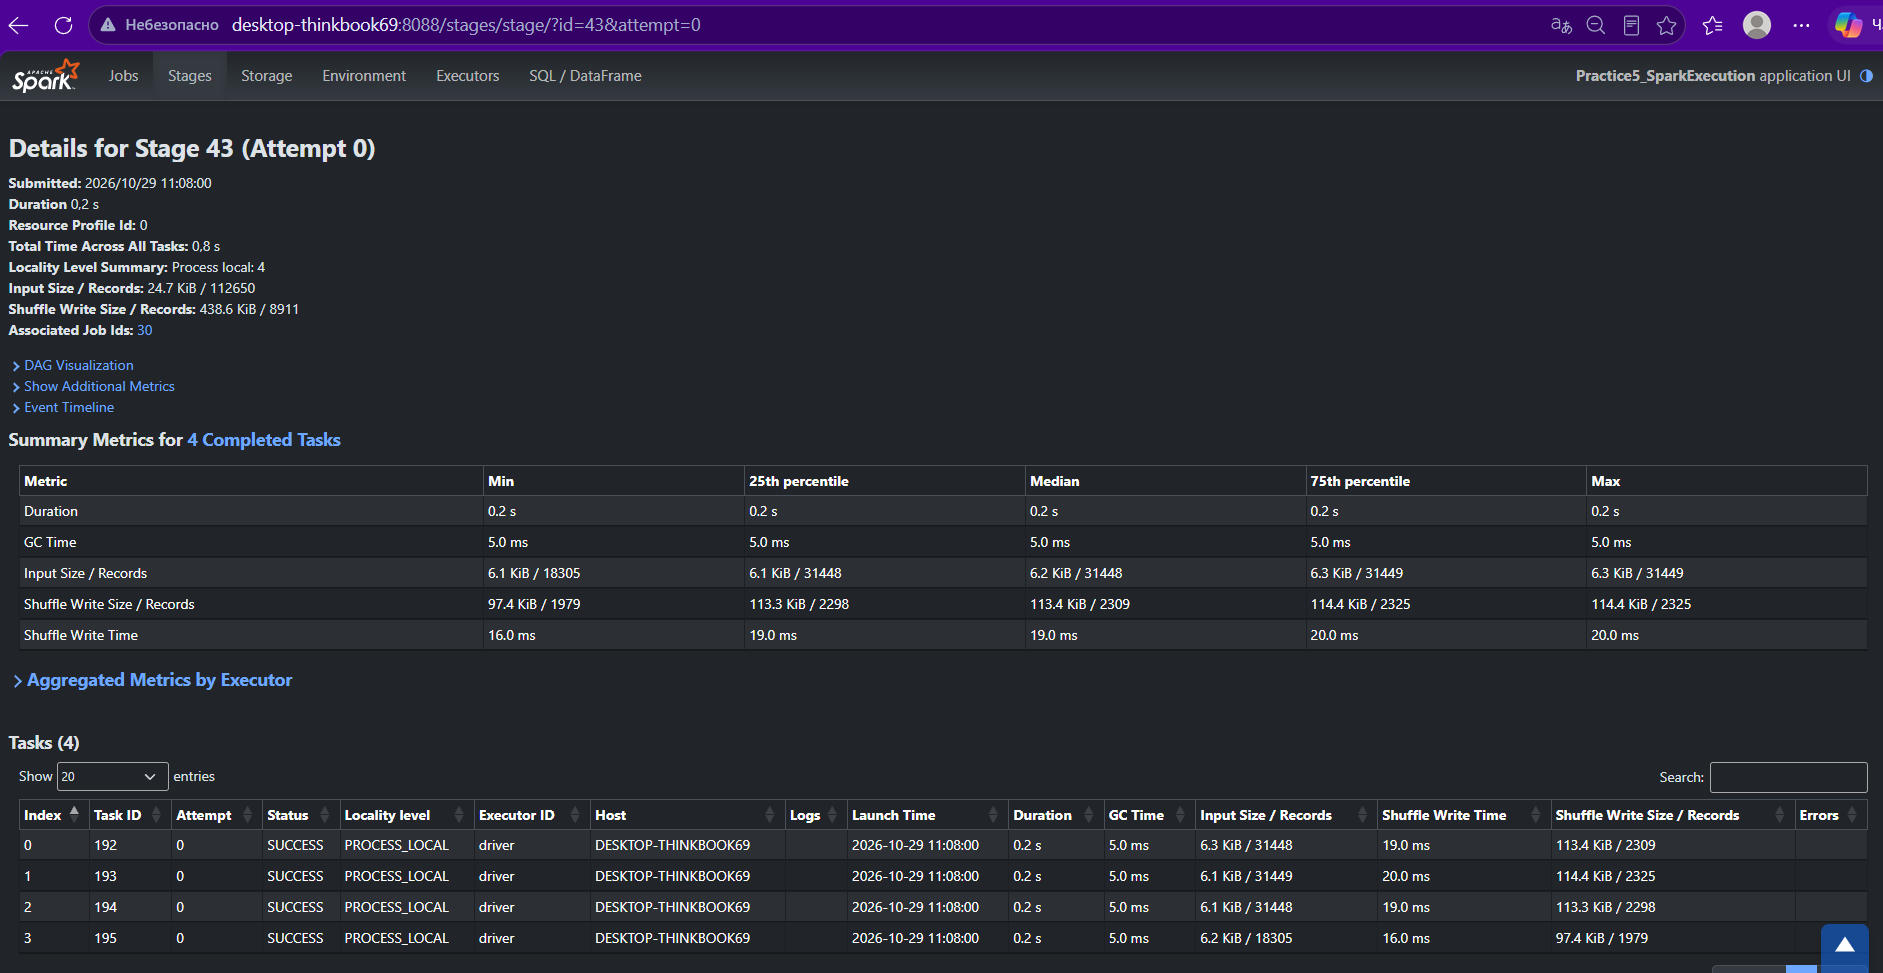

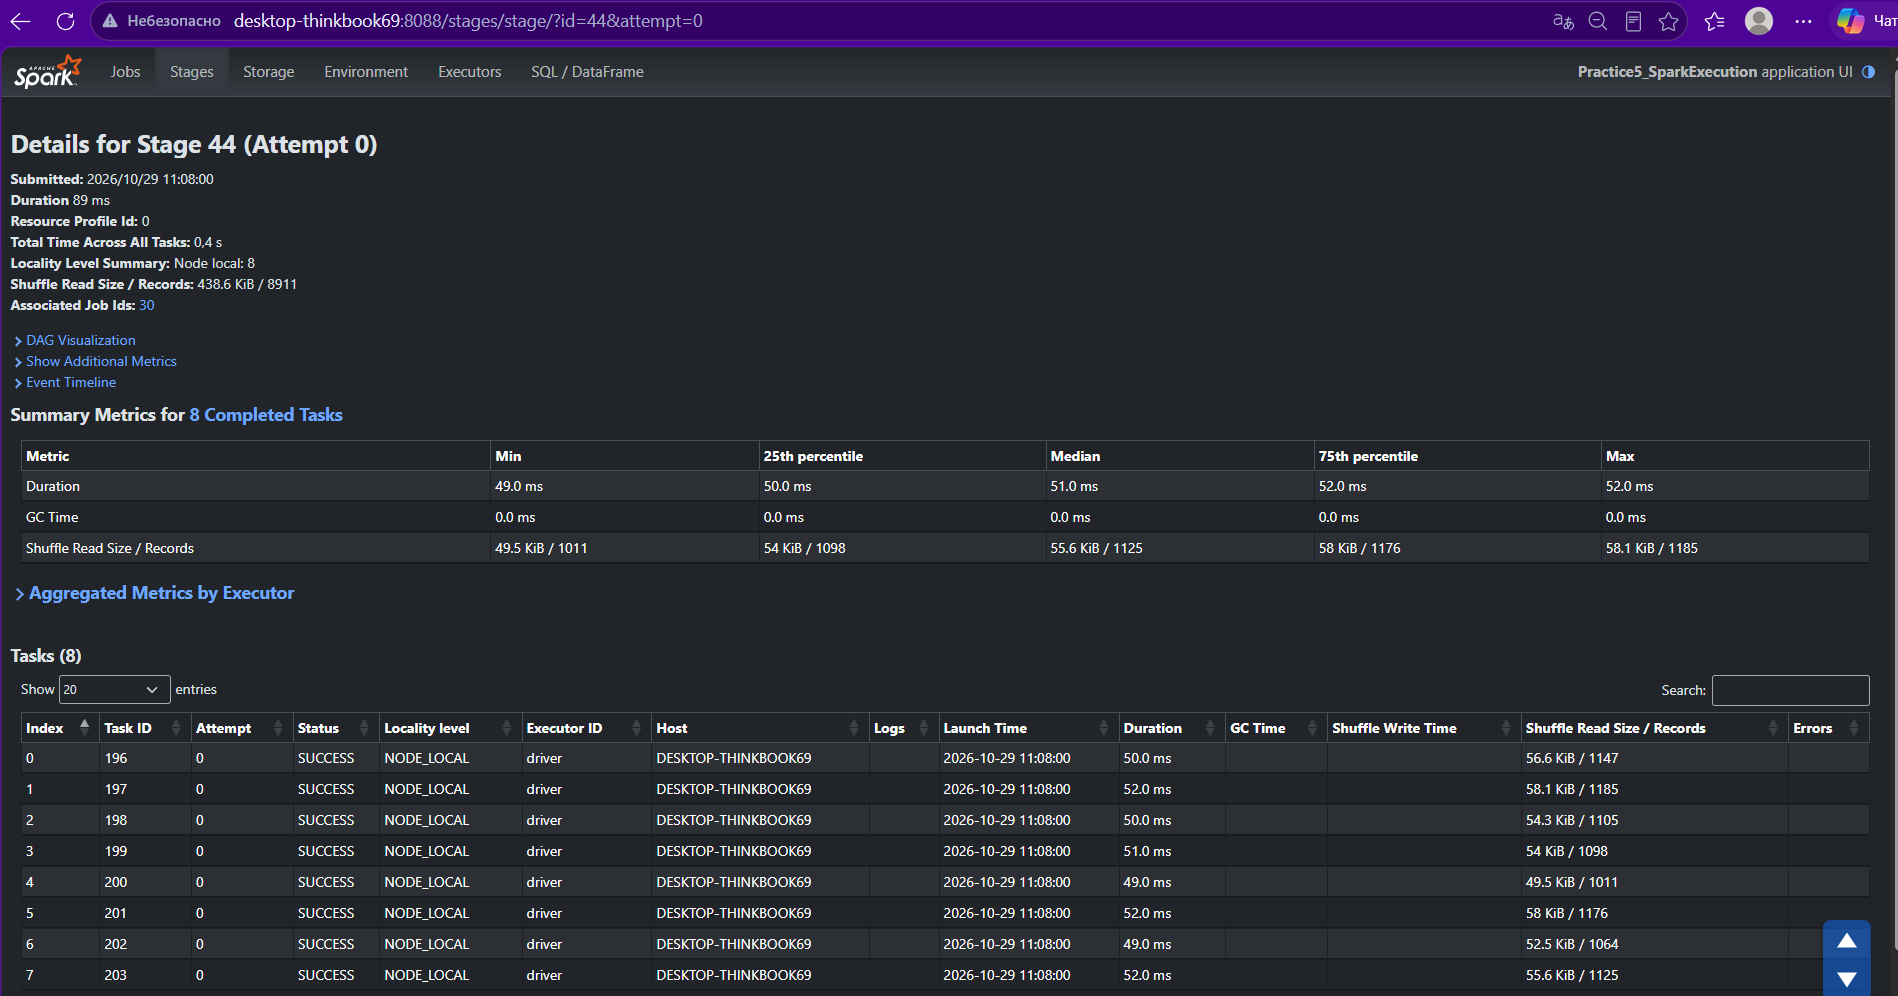

Группирует позиции заказов по продавцу и считает для каждого число товаров, суммарную выручку и среднюю цену. Результат сортируется по выручке, после чего показываются пять продавцов с наибольшей суммой.

In [12]:
sc.setJobGroup("P5_GROUPBY", "Shuffle: groupBy seller_id")

seller_stats = (
    items
    .groupBy("seller_id")
    .agg(
        F.count("*").alias("items"),
        F.round(F.sum("price"), 2).alias("revenue"),
        F.round(F.avg("price"), 2).alias("avg_price")
    )
    .orderBy(F.desc("revenue"))
)

seller_stats.show(5, truncate=False)

+--------------------------------+-----+---------+---------+
|seller_id                       |items|revenue  |avg_price|
+--------------------------------+-----+---------+---------+
|4869f7a5dfa277a7dca6462dcf3b52b2|1156 |229472.63|198.51   |
|53243585a1d6dc2643021fd1853d8905|410  |222776.05|543.36   |
|4a3ca9315b744ce9f8e9374361493884|1987 |200472.92|100.89   |
|fa1c13f2614d7b5c4749cbc52fecda94|586  |194042.03|331.13   |
|7c67e1448b00f6e969d365cea6b010ab|1364 |187923.89|137.77   |
+--------------------------------+-----+---------+---------+
only showing top 5 rows


#### Таблица 5. Пять продавцов с максимальной суммой price в order_items

| seller_id | items | revenue | avg_price |
| :--- | :--- | :--- | :--- |
| 4869f7a5dfa277a7dca6462dcf3b52b2 | 1156 | 229472.63 | 198.51 |
| 53243585a1d6dc2643021fd1853d8905 | 410 | 222776.05 | 543.36 |
| 4a3ca9315b744ce9f8e9374361493884 | 1987 | 200472.92 | 100.89 |
| fa1c13f2614d7b5c4749cbc52fecda94 | 586 | 194042.03 | 331.13 |
| 7c67e1448b00f6e969d365cea6b010ab | 1364 | 187923.89 | 137.77 |

Печатает физический план для агрегации по продавцам. В плане видно, что сначала выполняется частичная агрегация, затем данные перемешиваются по ключу продавца, после чего выполняется финальная агрегация и сортировка.

In [13]:
seller_stats.explain("formatted")

== Physical Plan ==
* Sort (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- Exchange (4)
         +- * HashAggregate (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [2]: [seller_id#150, price#152]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
ReadSchema: struct<seller_id:string,price:double>

(2) ColumnarToRow [codegen id : 1]
Input [2]: [seller_id#150, price#152]

(3) HashAggregate [codegen id : 1]
Input [2]: [seller_id#150, price#152]
Keys [1]: [seller_id#150]
Functions [3]: [partial_count(1), partial_sum(price#152), partial_avg(price#152)]
Aggregate Attributes [4]: [count#307L, sum#308, sum#309, count#310L]
Results [5]: [seller_id#150, count#311L, sum#312, sum#313, count#314L]

(4) Exchange
Input [5]: [seller_id#150, count#311L, sum#312, sum#313, count#314L]
Arguments: hashpartitioning(seller_id#150, 8), ENSURE_REQUIREMENTS, [plan_id=716]

(5) HashAggregate [codegen id : 2]

Строит учебный пример плана: фильтрует строки по цене, выбирает нужные столбцы, вычисляет дополнительную величину, группирует по продавцу и суммирует. Затем печатает физический план, чтобы показать порядок чтения, фильтрации, вычисления, перемешивания и агрегации.

In [14]:
plan_demo = (
    items
    .filter(F.col("price") >= 100)
    .select("seller_id", "price", "freight_value")
    .withColumn("gross", F.col("price") + F.col("freight_value"))
    .groupBy("seller_id")
    .agg(F.round(F.sum("gross"), 2).alias("gross_sum"))
)

plan_demo.explain("formatted")

== Physical Plan ==
* HashAggregate (7)
+- Exchange (6)
   +- * HashAggregate (5)
      +- * Project (4)
         +- * Filter (3)
            +- * ColumnarToRow (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [seller_id#150, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(price), GreaterThanOrEqual(price,100.0)]
ReadSchema: struct<seller_id:string,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [seller_id#150, price#152, freight_value#153]

(3) Filter [codegen id : 1]
Input [3]: [seller_id#150, price#152, freight_value#153]
Condition : (isnotnull(price#152) AND (price#152 >= 100.0))

(4) Project [codegen id : 1]
Output [2]: [seller_id#150, (price#152 + freight_value#153) AS gross#336]
Input [3]: [seller_id#150, price#152, freight_value#153]

(5) HashAggregate [codegen id : 1]
Input [2]: [seller_id#150, gross#336]
Keys [1]: [s

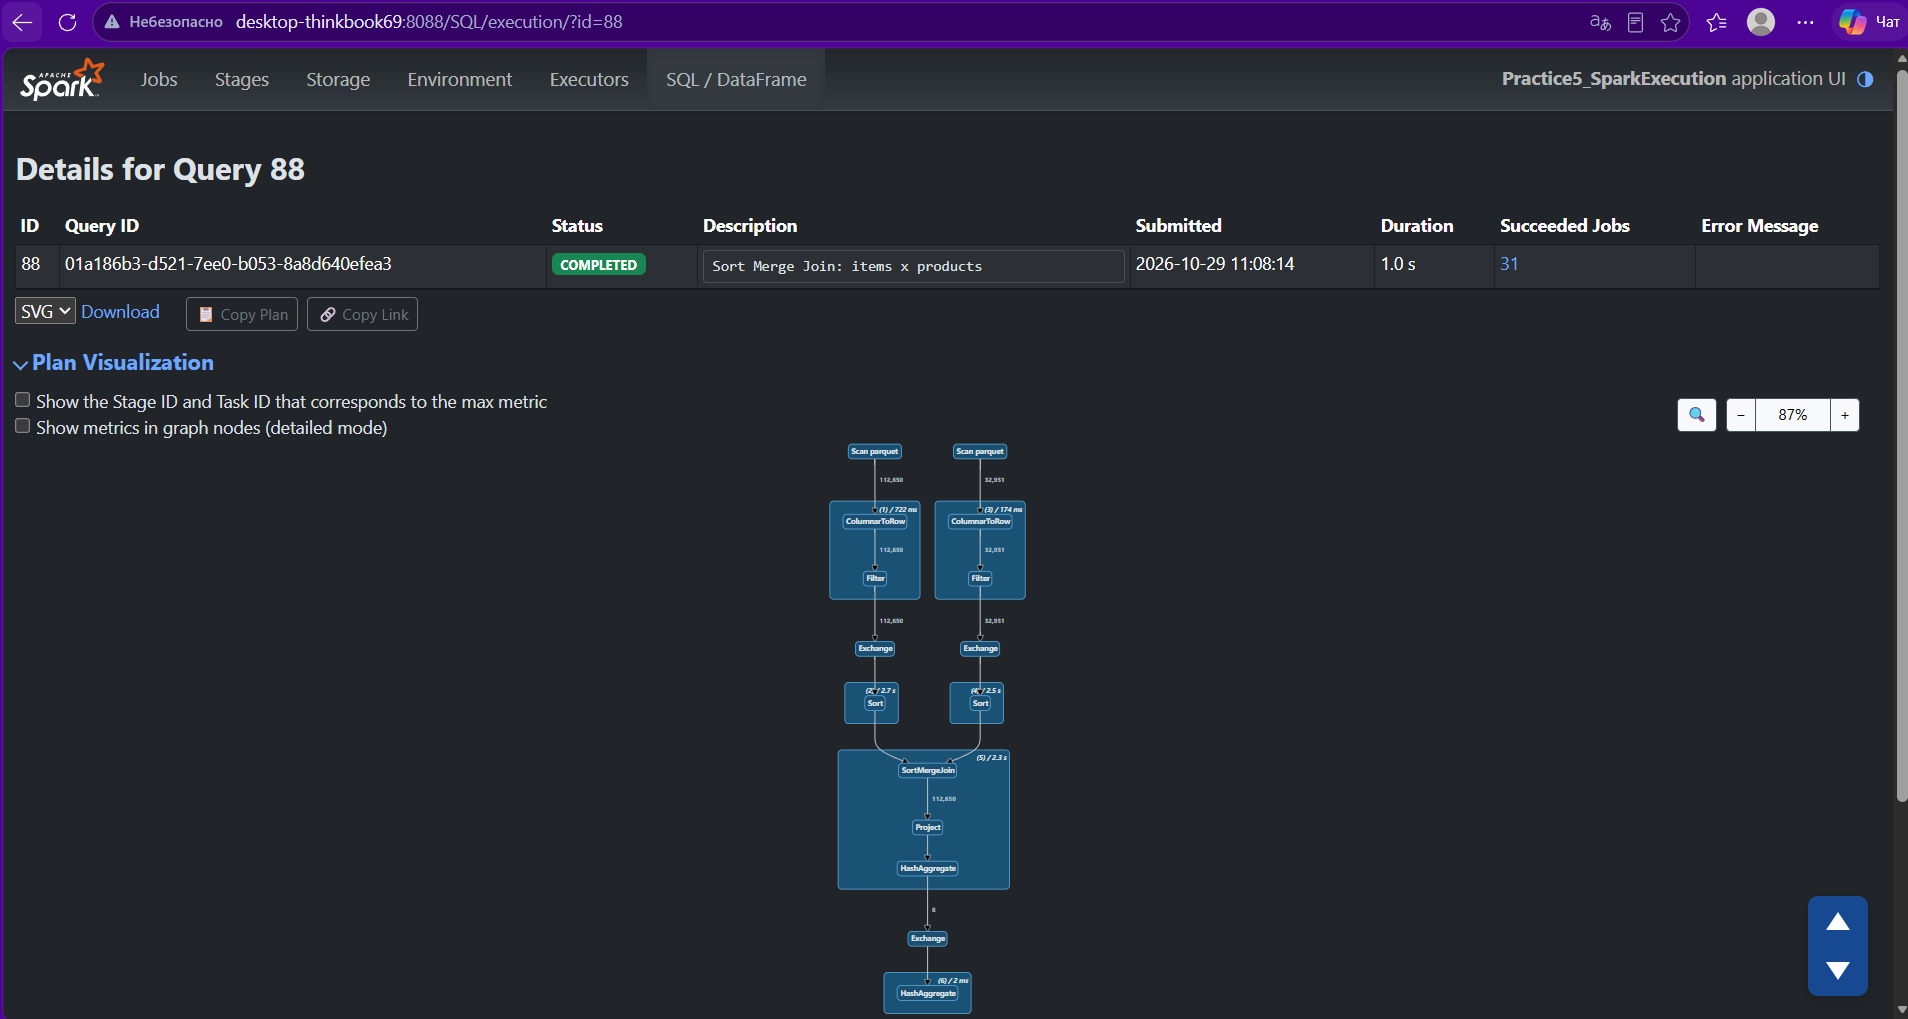

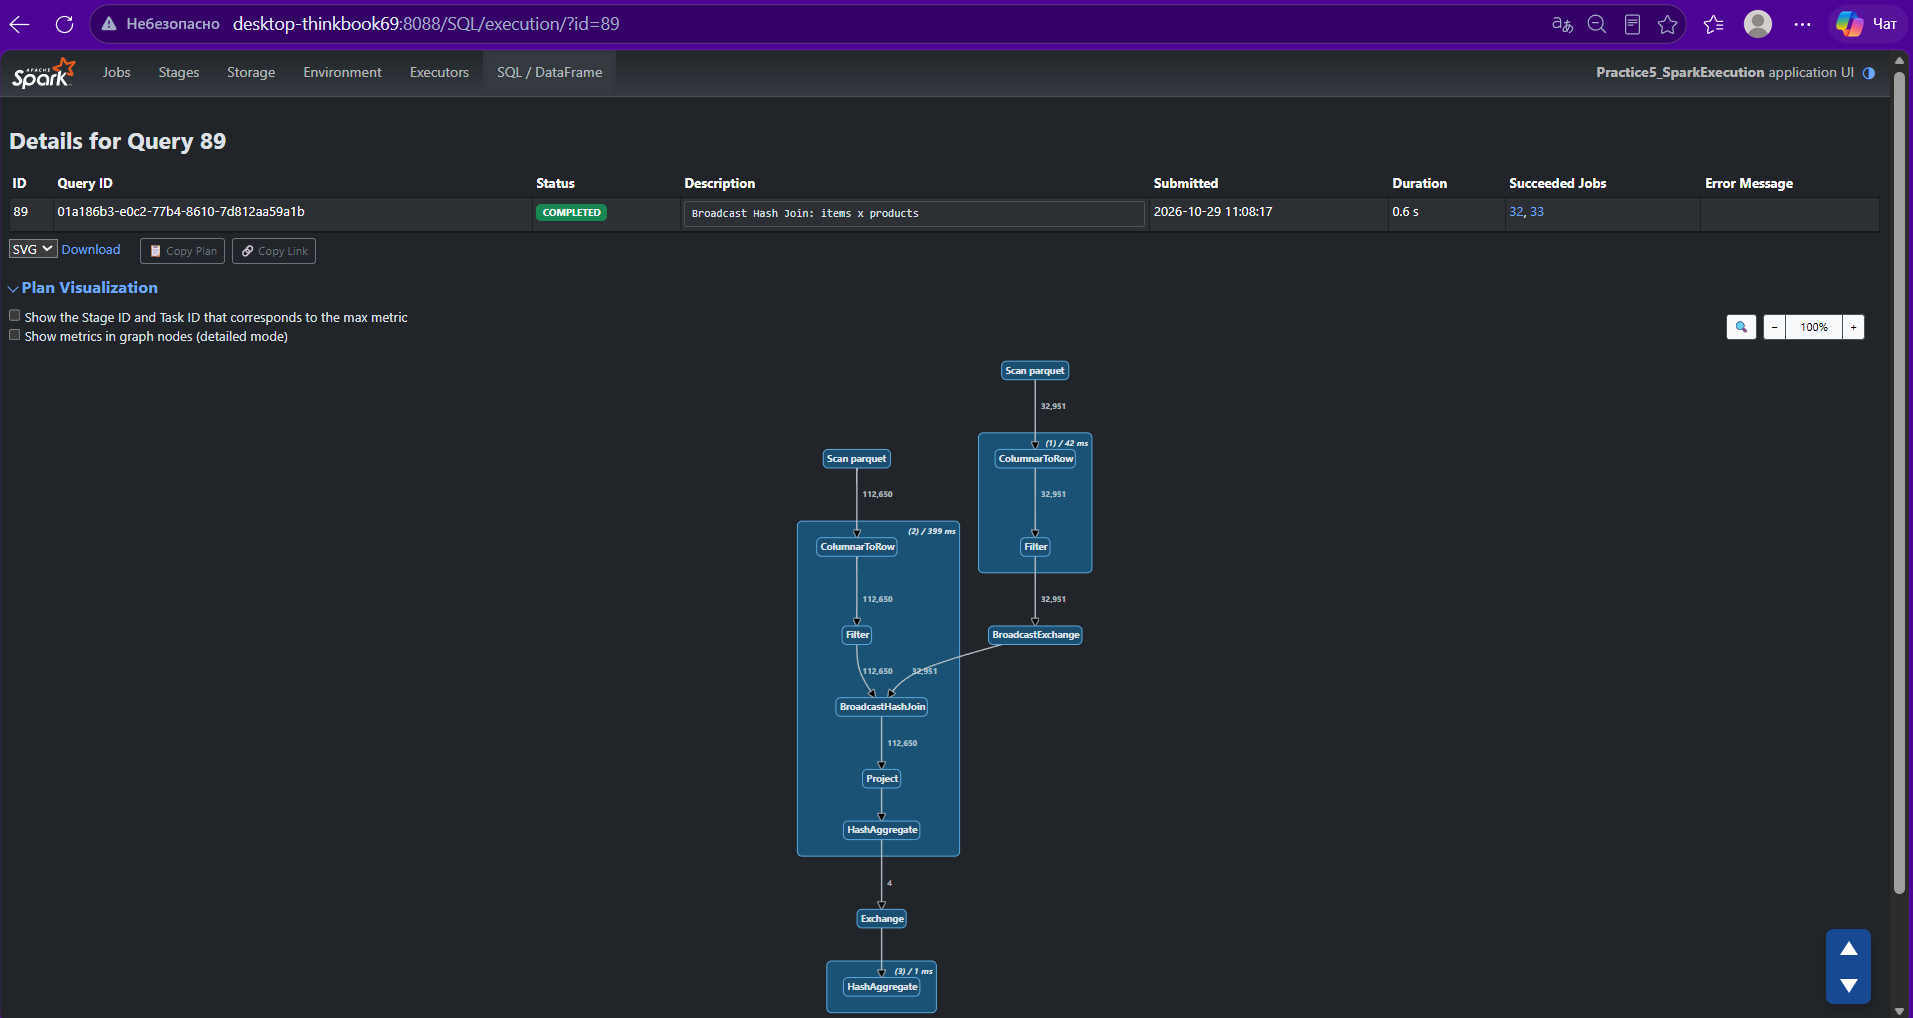

Выполняет соединение позиций заказов со справочником товаров в режиме сортировочно-слиятельного соединения. Печатает физический план и контрольное число строк результата; в плане должны быть видны перемешивание и сортировка обеих сторон.

In [15]:
sc.setJobGroup("P5_SMJ", "Sort Merge Join: items x products")

smj = (items.hint("merge")
       .join(products.hint("merge"), on="product_id", how="inner"))

smj.explain("formatted")
print("Rows:", smj.count())

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]

(3) Filter [codegen id : 1]
Input [7]: [order_id#147, o

Выполняет то же самое соединение, но маленький справочник товаров принудительно рассылается на все вычислительные слоты. Печатает план и число строк; результат должен совпасть с предыдущим, но физическая стратегия будет другой.

In [16]:
sc.setJobGroup("P5_BHJ", "Broadcast Hash Join: items x products")

bhj = items.join(
    F.broadcast(products), on="product_id", how="inner"
)

bhj.explain("formatted")
print("Rows:", bhj.count())

== Physical Plan ==
* Project (9)
+- * BroadcastHashJoin Inner BuildRight (8)
   :- * Filter (3)
   :  +- * ColumnarToRow (2)
   :     +- Scan parquet  (1)
   +- BroadcastExchange (7)
      +- * Filter (6)
         +- * ColumnarToRow (5)
            +- Scan parquet  (4)


(1) Scan parquet 
Output [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(product_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 2]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_date#151, price#152, freight_value#153]

(3) Filter [codegen id : 2]
Input [7]: [order_id#147, order_item_id#148, product_id#149, seller_id#150, shipping_limit_d

#### Таблица 6. Сравнение JOIN-экспериментов

| Показатель | Sort Merge Join | Broadcast Hash Join |
| :--- | :--- | :--- |
| Строк результата | 112 650 | 112 650 |
| Exchange большой стороны | Есть (hashpartitioning) | Нет |
| Shuffle Read / Write | ~3.7 MiB / ~3.8 MiB | 236 B / 0 B |
| Jobs / Stages | 1 Job / 4 Stages | 1 Job / 3 Stages |
| Время, с | ~0.83 | ~0.23 |

Очищает ранее сохранённые кэши и создаёт промежуточный фрейм данных: к позициям заказов присоединяются маленькие справочники товаров и продавцов, затем добавляется вычисляемая денежная величина. Также объявляются две функции для двух разных агрегаций по этому промежуточному результату.

In [17]:
spark.catalog.clearCache()

products_small = products.select(
    "product_id", "product_category_name"
)
sellers_small = sellers.select(
    "seller_id", "seller_state"
)

joined = (
    items
    .join(F.broadcast(products_small), "product_id", "left")
    .join(F.broadcast(sellers_small), "seller_id", "left")
    .withColumn(
        "gross_value",
        F.col("price") + F.col("freight_value")
    )
)

def action_category(df):
    return (
        df.groupBy("product_category_name")
        .agg(F.sum("gross_value").alias("gross"))
        .agg(F.sum("gross").alias("checksum"))
        .first()[0]
    )

def action_state(df):
    return (
        df.groupBy("seller_state")
        .agg(F.sum("gross_value").alias("gross"))
        .agg(F.sum("gross").alias("checksum"))
        .first()[0]
    )

Выполняет две агрегации над промежуточным фреймом данных без сохранения в кэш. Замеряется время каждого действия и проверяется, что промежуточный результат не кэширован; это базовый вариант для сравнения.

In [18]:
sc.setJobGroup("P5_NOCACHE", "Два действия без сохранения")

t0 = perf_counter()
_ = action_category(joined)
t1 = perf_counter()
_ = action_state(joined)
t2 = perf_counter()

print(f"Action 1: {t1 - t0:.3f} s")
print(f"Action 2: {t2 - t1:.3f} s")
print("is_cached:", joined.is_cached)

Action 1: 0.825 s
Action 2: 0.626 s
is_cached: False


Сохраняет промежуточный результат в памяти и на диске, затем первым действием материализует кэш. После этого повторяет две агрегации уже по сохранённому результату, замеряет время и в конце освобождает кэш, проверяя, что он снят.

In [19]:
cached = joined.persist(StorageLevel.MEMORY_AND_DISK)
print("После persist:", cached.is_cached)

# Materialization: первый Action заполняет кэш
t0 = perf_counter()
materialized_rows = cached.count()
t1 = perf_counter()

# Повторные Actions используют материализованный DataFrame
_ = action_category(cached)
t2 = perf_counter()
_ = action_state(cached)
t3 = perf_counter()

print("Rows:", materialized_rows)
print(f"Materialization: {t1 - t0:.3f} s")
print(f"Cached action 1: {t2 - t1:.3f} s")
print(f"Cached action 2: {t3 - t2:.3f} s")

cached.unpersist(blocking=True)
print("После unpersist:", cached.is_cached)

После persist: True
Rows: 112650
Materialization: 1.244 s
Cached action 1: 0.500 s
Cached action 2: 0.268 s
После unpersist: False


#### Таблица 7. Сравнение повторных вычислений с кэшем и без него

| Вариант | Подготовка/материализация, с | Action 1, с | Action 2, с |
| :--- | :--- | :--- | :--- |
| Без persist | — | 1.487 | 0.887 |
| MEMORY_AND_DISK | 1.932 | 0.615 | 0.431 |

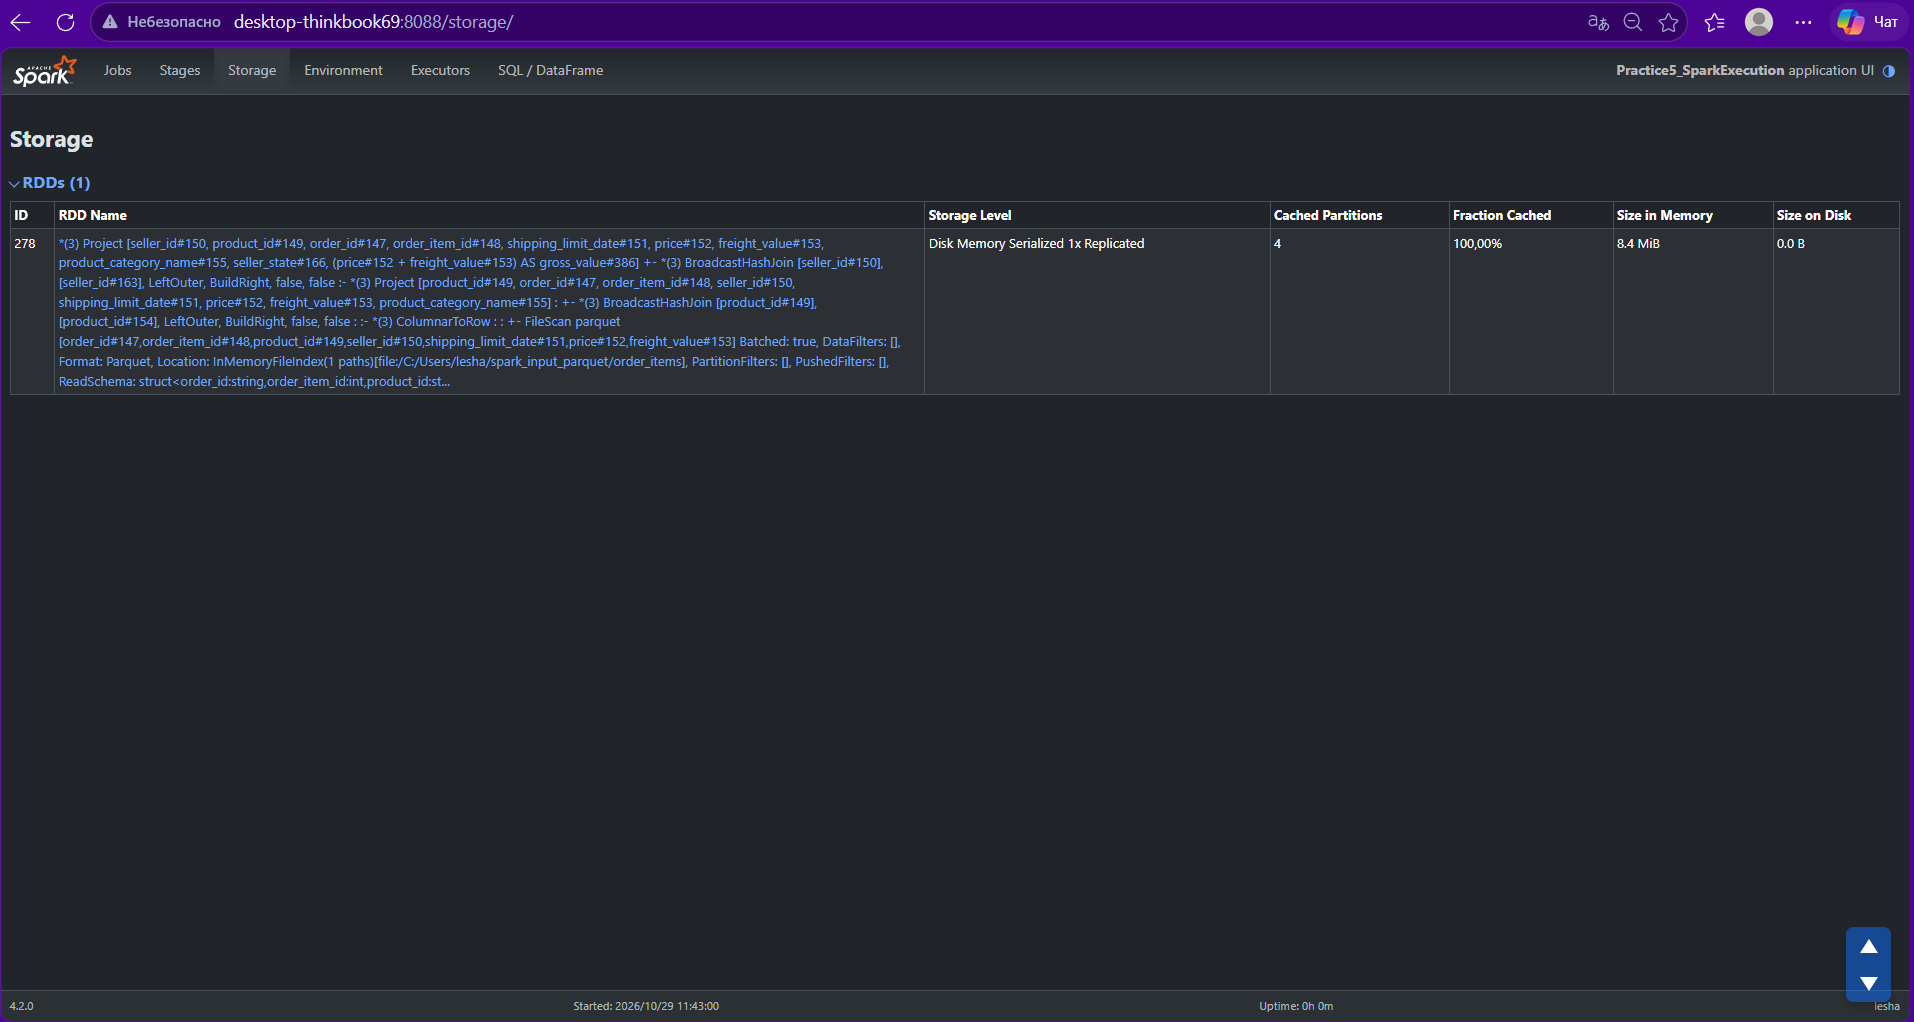

Проводит бенчмарк на синтетическом наборе чисел: меняет число входных разделов, для каждого варианта делает прогревочный запуск и несколько повторных измерений. Считает медиану времени и контрольную сумму, чтобы результаты были сопоставимы.

In [20]:
from statistics import median

N = 2_000_000
P_VALUES = [1, 2, 4, 8, 16, 32]
spark.conf.set("spark.sql.shuffle.partitions", "8")

def run_benchmark(p, repeats=3):
    times = []
    checksum = None
    for _ in range(repeats):
        df = (
            spark.range(0, N, 1, numPartitions=p)
            .withColumn("key", (F.col("id") % 1000).cast("int"))
            .withColumn("value", F.sqrt(F.col("id") + 1.0))
        )
        t0 = perf_counter()
        checksum = (
            df.groupBy("key")
            .agg(F.sum("value").alias("s"))
            .agg(F.sum("s").alias("checksum"))
            .first()[0]
        )
        times.append(perf_counter() - t0)
    return times, median(times), checksum

# Прогрев
_ = run_benchmark(4, repeats=1)

results = []
for p in P_VALUES:
    times, med, checksum = run_benchmark(p, repeats=3)
    results.append((p, *times, med))
    print(p, times, med, checksum)

1 [0.30589530011639, 0.1630430999211967, 0.14749830006621778] 0.1630430999211967 1885618790.063052
2 [0.3344332999549806, 0.24696399993263185, 0.2997828000225127] 0.2997828000225127 1885618790.0630507
4 [0.23320419993251562, 0.1993398000486195, 0.21945879980921745] 0.21945879980921745 1885618790.0630512
8 [0.35943669988773763, 0.3933793001342565, 0.27382060000672936] 0.35943669988773763 1885618790.0630512
16 [0.5190837001428008, 0.35623699985444546, 0.40412590000778437] 0.40412590000778437 1885618790.0630512
32 [0.6172577000688761, 0.5313017999287695, 0.41456610010936856] 0.5313017999287695 1885618790.0630512


#### Таблица 8. Влияние числа входных partitions на время

| p | Run 1, с | Run 2, с | Run 3, с | Median, с | S(p)=T(1)/T(p) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| 1 | 0.407 | 0.239 | 0.220 | 0.239 | 1.00 |
| 2 | 0.523 | 0.387 | 0.341 | 0.387 | 0.62 |
| 4 | 0.323 | 0.292 | 0.330 | 0.323 | 0.74 |
| 8 | 0.549 | 0.358 | 0.311 | 0.357 | 0.67 |
| 16 | 0.689 | 0.408 | 0.395 | 0.407 | 0.59 |
| 32 | 0.847 | 0.554 | 0.602 | 0.602 | 0.40 |

Фиксирует входной фрейм данных на восьми разделах и отдельно меняет только число разделов после перемешивания. Для каждого значения выполняет группировку по штату и замеряет время, показывая, что входные разделы и разделы после перемешивания — разные настройки.

In [21]:
geo8 = geo.repartition(8)
Q_VALUES = [2, 4, 8, 16, 32]

for q in Q_VALUES:
    spark.conf.set("spark.sql.shuffle.partitions", str(q))
    t0 = perf_counter()
    rows = (
        geo8.groupBy("geolocation_state")
        .count()
        .count()
    )
    elapsed = perf_counter() - t0
    print(f"q={q:2d}; groups={rows}; time={elapsed:.3f}s")

# Возвращаем базовую настройку
spark.conf.set("spark.sql.shuffle.partitions", "8")

q= 2; groups=27; time=1.231s
q= 4; groups=27; time=0.571s
q= 8; groups=27; time=0.630s
q=16; groups=27; time=0.546s
q=32; groups=27; time=0.721s


Записывает один и тот же набор данных в Parquet с разным числом выходных разделов. Для каждого варианта считает количество файлов, общий размер и средний размер файла, чтобы показать связь между числом разделов и проблемой маленьких файлов.

In [22]:
OUT_SMALL = Path("small_files_experiment")
OUT_SMALL.mkdir(exist_ok=True)

def write_and_measure(p):
    path = OUT_SMALL / f"p_{p}"
    (
        items.repartition(p)
        .write.mode("overwrite")
        .parquet(str(path))
    )
    files = list(path.glob("part-*.parquet"))
    sizes = [f.stat().st_size for f in files]
    total_mib = sum(sizes) / 1024**2
    avg_kib = (sum(sizes) / len(sizes) / 1024) if sizes else 0
    return len(files), total_mib, avg_kib

for p in [1, 4, 16, 64]:
    print(p, write_and_measure(p))

1 (1, 6.456236839294434, 6611.1865234375)
4 (4, 7.432483673095703, 1902.7158203125)
16 (16, 8.732264518737793, 558.8649291992188)
64 (64, 10.285961151123047, 164.57537841796875)


#### Таблица 9. Связь partitions и part-файлов

| p | part-файлов | Общий размер, MiB | Средний файл, KiB |
| :--- | :--- | :--- | :--- |
| 1 | 1 | 6.46 | 6611.19 |
| 4 | 4 | 7.43 | 1902.72 |
| 16 | 16 | 8.73 | 558.86 |
| 64 | 64 | 10.29 | 164.58 |

Включает адаптивное выполнение запросов, задаёт большее число разделов после перемешивания и повторяет группировку по штату. Печатает адаптивный план и выполняет сбор результата, после чего возвращает прежние настройки; это показывает, что оптимизатор может менять выполнение уже после старта.

In [23]:
spark.conf.set("spark.sql.adaptive.enabled", "true")
spark.conf.set("spark.sql.shuffle.partitions", "32")

adaptive = (
    geo
    .groupBy("geolocation_state")
    .count()
)
adaptive.explain("formatted")
adaptive.collect()

print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))

spark.conf.set("spark.sql.adaptive.enabled", "false")
spark.conf.set("spark.sql.shuffle.partitions", "8")

== Physical Plan ==
AdaptiveSparkPlan (5)
+- HashAggregate (4)
   +- Exchange (3)
      +- HashAggregate (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [1]: [geolocation_state#146]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/geolocation]
ReadSchema: struct<geolocation_state:string>

(2) HashAggregate
Input [1]: [geolocation_state#146]
Keys [1]: [geolocation_state#146]
Functions [1]: [partial_count(1)]
Aggregate Attributes [1]: [count#1743L]
Results [2]: [geolocation_state#146, count#1744L]

(3) Exchange
Input [2]: [geolocation_state#146, count#1744L]
Arguments: hashpartitioning(geolocation_state#146, 32), ENSURE_REQUIREMENTS, [plan_id=3025]

(4) HashAggregate
Input [2]: [geolocation_state#146, count#1744L]
Keys [1]: [geolocation_state#146]
Functions [1]: [count(1)]
Aggregate Attributes [1]: [count(1)#1742L]
Results [2]: [geolocation_state#146, count(1)#1742L AS count#1735L]

(5) AdaptiveSparkPlan
Output [2]: [geolocation_state#146, 

#### Таблица 10. Журнал наблюдений по Spark UI

| Эксперимент | Jobs | Stages | Tasks в ключевой Stage | Shuffle Write | Shuffle Read | Что подтверждает UI |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| groupBy seller_id | 1 | 2 | 8 | 438.6 KiB | 438.6 KiB | Наличие Exchange и Shuffle между стадиями (Stages 43, 44) |
| repartition(4) | 1 | 2 | 8 | 248.0 B | 248.0 B | Полное перемешивание данных (Stages 38, 39) |
| Sort Merge Join | 1 | 4 | 8 | ~3.8 MiB | ~3.7 MiB | Shuffle обеих сторон перед Join (Stages 45-48) |
| Broadcast Hash Join | 1 | 3 | 4 | 0 B | 236.0 B | Отсутствие полного Shuffle, передача через Broadcast (Stages 49-51) |
| persist + повторный Action | 3 | 3 | 8 | 470.0 B | 3.1 KiB | Данные берутся из кэша (Storage), время выполнения действий резко падает по сравнению с P5_NOCACHE (Stages 66-71) |

Останавливает сессию Spark. После этого интерфейс наблюдения перестаёт быть активным.

In [24]:
spark.stop()

### **Выводы по разделу 1**

1. Ленивые вычисления подтверждены. Построение нового фрейма данных через выбор столбцов, фильтрацию и добавление вычисляемого столбца не запускает работу; реальное чтение и обработка начинаются только после действия подсчёта строк.

2. Разделы — это логические блоки данных, а не процессорные ядра. Число входных разделов может совпадать с числом доступных слотов, но строки распределены неравномерно: большинство разделов содержат десятки тысяч строк, а один — заметно меньше.

3. Перекос данных является свойством самих данных. В таблице геолокации один штат занимает более сорока процентов строк, затем идут несколько крупных штатов, а остальные представлены слабее; поэтому группировка и разбиение по такому ключу могут давать неравномерную нагрузку.

4. Перераспределение и объединение разделов дают одинаковое итоговое число разделов, но разный механизм. Полное перераспределение выравнивает размеры разделов почти идеально, а объединение соседних разделов сохраняет исходный перекос, хотя и требует меньше перемешивания.

5. Физическая стратегия соединения и наличие перемешивания определяют стоимость. Сортировочно-слиятельное соединение перемешивает и сортирует обе стороны, а широковещательное хеш-соединение рассылает маленький справочник и не перемешивает большую сторону; при одинаковом результате число стадий и время заметно различаются. Сохранение промежуточного результата помогает только при повторном использовании, потому что сначала нужно потратить время на материализацию.

### **Ограничения локального стенда**

1. Это одна локальная машина, а не распределённый кластер. Все операции перемешивания выполняются внутри одного процесса и одного компьютера, без реальной сети; поэтому абсолютные времена и объёмы обмена нельзя переносить на кластер.

2. Результаты зависят от железа, прогрева, фоновой нагрузки и выбранной конфигурации. Основные опыты выполнены с отключённым адаптивным выполнением и на одном учебном наборе данных, поэтому корректно сравнивать направления и механизмы внутри одной сессии, а не превращать локальные секунды и найденные оптимальные значения в универсальное правило.

# **2. Самостоятельный раздел по ecommerce.sqlite**

In [25]:
import os
import sys

# Настройка Java (из вашего успешного опыта)
os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jdk-17"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"\bin;" + os.environ["PATH"]

# Настройка Hadoop (из вашей 3-й практики)
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["hadoop.home.dir"] = r"C:\hadoop"

# Настройка Python для PySpark
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F
from pyspark import StorageLevel

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Practice5_SparkExecution")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.adaptive.enabled", "false")
    .config("spark.sql.autoBroadcastJoinThreshold", "-1")
    .config("spark.ui.port", "8088")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"))
print("Spark UI:", spark.sparkContext.uiWebUrl)

sc = spark.sparkContext

sc.setJobGroup(
    "P5_BASELINE",
    "Практика 5: базовая проверка Spark UI", interruptOnCancel=True
)

Master: local[*]
Default parallelism: 12
Shuffle partitions: 8
AQE: false
Spark UI: http://DESKTOP-THINKBOOK69:8088


Вывод по блоку 1. Сессия поднялась в локальном режиме: несколько ядер одного компьютера имитируют кластер. Адаптивное выполнение отключено намеренно — иначе Spark сам решал бы, сколько оставить разделов и какую стратегию соединения выбрать, и разница в планах была бы вызвана оптимизатором, а не нашим кодом. Число разделов после перемешивания зафиксировано, чтобы все последующие запросы имели предсказуемое число параллельных задач. Напечатанные параметры — «паспорт» стенда.

In [26]:
from pyspark.sql import functions as F
from pyspark import StorageLevel
from time import perf_counter
from statistics import median
from pathlib import Path

PARQUET = Path("spark_input_parquet")
items   = spark.read.parquet(str(PARQUET / "order_items"))
sellers = spark.read.parquet(str(PARQUET / "sellers"))

print("order_items rows:", items.count(),   "| partitions:", items.rdd.getNumPartitions())
print("sellers     rows:", sellers.count(), "| partitions:", sellers.rdd.getNumPartitions())

order_items rows: 112650 | partitions: 4
sellers     rows: 3095 | partitions: 1


Вывод по блоку 2. Таблицы различаются более чем в тридцать раз, и от этого зависит стратегия соединения. Широковещательное соединение копирует маленькую таблицу на каждый вычислительный слот, и каждая задача ищет совпадения в готовой копии справочника. Копирование дёшево только пока таблица действительно мала; для десятков миллионов строк это съело бы память исполнителей. Поэтому наш справочник — естественный кандидат на рассылку. Заодно видно, что основная таблица разбита всего на 4 раздела при 12 ядрах: до перемешивания параллельно смогут работать максимум 4 задачи.

In [27]:
sc.setJobGroup("SELF_LAZY", "Lazy evaluation: 3 transformations")

prepared = (items
    .filter(F.col("price") > 0)
    .select("seller_id", "price", "freight_value")
    .withColumn("gross", F.col("price") + F.col("freight_value"))
)
print("type:", type(prepared).__name__)

t0 = perf_counter()
n = prepared.count()
elapsed = perf_counter() - t0
print("rows:", n, f"| elapsed: {elapsed:.3f}s")

type: DataFrame
rows: 112650 | elapsed: 0.160s


Вывод по блоку 3. Три преобразования не запустили вычислений — это "ленивость" Spark: преобразования только записывают рецепт, готовить по нему Spark начинает при запросе результата. Действие подсчёта заставило прочитать файлы, применить фильтр, отбросить столбцы, вычислить новый и вернуть число за 0,203 с. Практический вывод: замерять надо вокруг действий, а не вокруг преобразований, иначе получим время построения плана, которое ничего не говорит о стоимости обработки.

In [28]:
sc.setJobGroup("SELF_REPART", "repartition vs coalesce")

skewed8 = items.repartition(8, "seller_id")
repart2 = skewed8.repartition(2)
coal2   = skewed8.coalesce(2)

print("skewed8:", skewed8.rdd.getNumPartitions())
print("repart2:", repart2.rdd.getNumPartitions())
print("coal2:  ", coal2.rdd.getNumPartitions())

print("\n=== repartition(2) ===")
repart2.explain("formatted")
print("\n=== coalesce(2) ===")
coal2.explain("formatted")

skewed8: 8
repart2: 2
coal2:   2

=== repartition(2) ===
== Physical Plan ==
Exchange (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [7]: [order_id#1745, order_item_id#1746, product_id#1747, seller_id#1748, shipping_limit_date#1749, price#1750, freight_value#1751]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [7]: [order_id#1745, order_item_id#1746, product_id#1747, seller_id#1748, shipping_limit_date#1749, price#1750, freight_value#1751]

(3) Exchange
Input [7]: [order_id#1745, order_item_id#1746, product_id#1747, seller_id#1748, shipping_limit_date#1749, price#1750, freight_value#1751]
Arguments: RoundRobinPartitioning(2), REPARTITION_BY_NUM, [plan_id=3203]



=== coalesce(2) ===
== Physical Plan ==
Coalesce (4)

Вывод по блоку 4. Оба варианта дали по два раздела, но разными путями. Перераспределение полностью перемешало строки по кругу — дорого, но равномерно. Объединение соседних разделов ничего не перемешало: оно просто сшило пары существующих разделов, сохранив перекос. Смысл: одинаковое число разделов не означает одинаковую стоимость. Нужно перераспределить данные — без обмена не обойтись; нужно лишь уменьшить число файлов — объединение предпочтительнее, оно не платит за перемешивание.

In [29]:
sc.setJobGroup("SELF_GROUPBY", "groupBy seller_state")

joined_state = items.join(sellers, on="seller_id", how="left")

state_stats = (joined_state
    .groupBy("seller_state")
    .agg(
        F.count("*").alias("items"),
        F.round(F.sum("price"), 2).alias("revenue"),
        F.round(F.avg("price"), 2).alias("avg_price")
    )
    .orderBy(F.desc("revenue"))
)

state_stats.explain("formatted")
t0 = perf_counter(); state_stats.show(5, truncate=False); elapsed = perf_counter() - t0
print(f"show elapsed: {elapsed:.3f}s")

== Physical Plan ==
* Sort (16)
+- Exchange (15)
   +- * HashAggregate (14)
      +- Exchange (13)
         +- * HashAggregate (12)
            +- * Project (11)
               +- * SortMergeJoin LeftOuter (10)
                  :- * Sort (4)
                  :  +- Exchange (3)
                  :     +- * ColumnarToRow (2)
                  :        +- Scan parquet  (1)
                  +- * Sort (9)
                     +- Exchange (8)
                        +- * Filter (7)
                           +- * ColumnarToRow (6)
                              +- Scan parquet  (5)


(1) Scan parquet 
Output [2]: [seller_id#1748, price#1750]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
ReadSchema: struct<seller_id:string,price:double>

(2) ColumnarToRow [codegen id : 1]
Input [2]: [seller_id#1748, price#1750]

(3) Exchange
Input [2]: [seller_id#1748, price#1750]
Arguments: hashpartitioning(seller_id#1748, 8), ENSURE_REQUIREMENTS, [plan_id

Вывод по блоку 5. Запрос дороже простого подсчёта по двум причинам. Сначала пришлось присоединить справочник — это соединение со своим перемешиванием и сортировкой. Затем сама агрегация идёт в две фазы: сначала локально по партициям, чтобы резко уменьшить объём — популярный штат сжимается из десятков тысяч строк в одну запись, — и только потом перемешиваются компактные частичные результаты. Сверху ещё одно перемешивание — цена сортировки по выручке. Основная стоимость — именно эти обмены, а не арифметика.

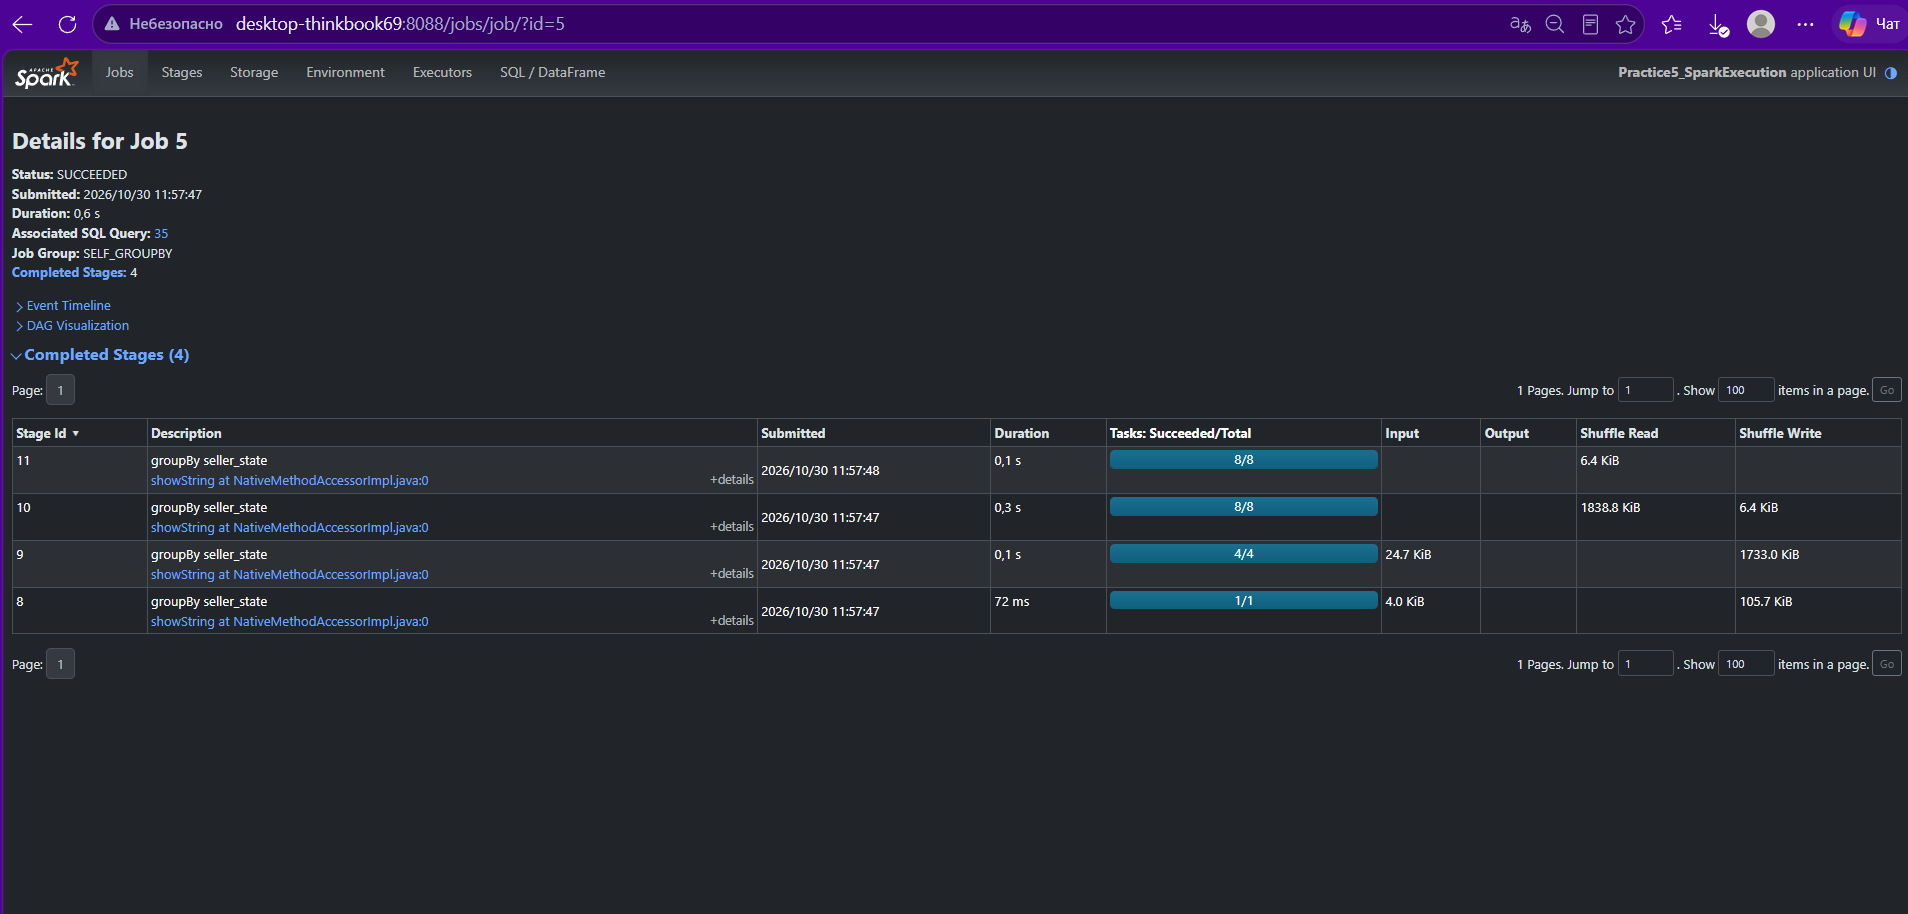

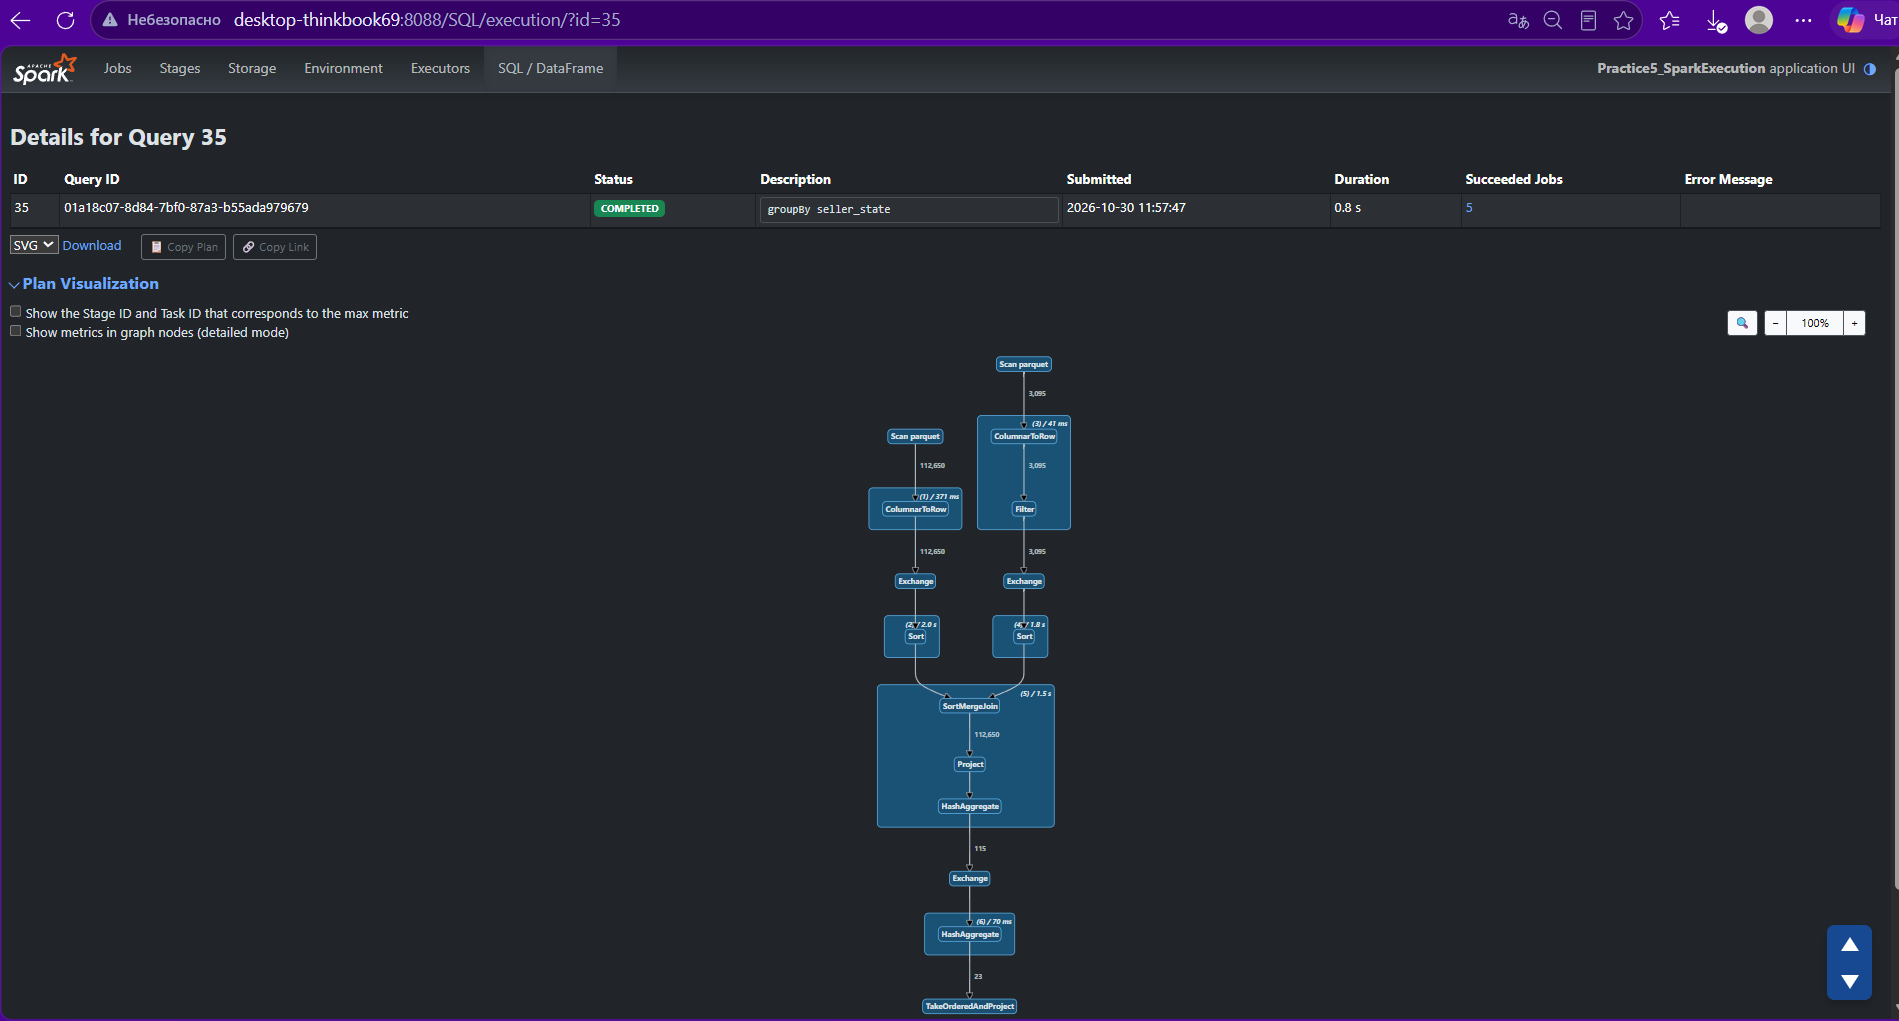

In [30]:
sc.setJobGroup("SELF_SMJ", "SortMergeJoin items x sellers")
smj = items.hint("merge").join(sellers.hint("merge"), on="seller_id", how="inner")
smj.explain("formatted")
t0 = perf_counter(); n_smj = smj.count(); t_smj = perf_counter() - t0
print(f"SMJ rows={n_smj} time={t_smj:.3f}s")

sc.setJobGroup("SELF_BHJ", "BroadcastHashJoin items x sellers")
bhj = items.join(F.broadcast(sellers), on="seller_id", how="inner")
bhj.explain("formatted")
t0 = perf_counter(); n_bhj = bhj.count(); t_bhj = perf_counter() - t0
print(f"BHJ rows={n_bhj} time={t_bhj:.3f}s")

== Physical Plan ==
* Project (12)
+- * SortMergeJoin Inner (11)
   :- * Sort (5)
   :  +- Exchange (4)
   :     +- * Filter (3)
   :        +- * ColumnarToRow (2)
   :           +- Scan parquet  (1)
   +- * Sort (10)
      +- Exchange (9)
         +- * Filter (8)
            +- * ColumnarToRow (7)
               +- Scan parquet  (6)


(1) Scan parquet 
Output [7]: [order_id#1745, order_item_id#1746, product_id#1747, seller_id#1748, shipping_limit_date#1749, price#1750, freight_value#1751]
Batched: true
Location: InMemoryFileIndex [file:/C:/Users/lesha/spark_input_parquet/order_items]
PushedFilters: [IsNotNull(seller_id)]
ReadSchema: struct<order_id:string,order_item_id:int,product_id:string,seller_id:string,shipping_limit_date:timestamp,price:double,freight_value:double>

(2) ColumnarToRow [codegen id : 1]
Input [7]: [order_id#1745, order_item_id#1746, product_id#1747, seller_id#1748, shipping_limit_date#1749, price#1750, freight_value#1751]

(3) Filter [codegen id : 1]
Input [7]: [or

Вывод по блоку 6. Логически запросы идентичны, вернули те же строки, но механизм разный. Сортировочно-слиятельное соединение перемешивает и сортирует обе стороны — два обмена и две сортировки, отсюда 0,481 с. Широковещательное использует знание, что справочник мал: он копируется на исполнители, большая таблица читается на месте без обмена — отсюда 0,233 с. Граница применимости: пока маленькая сторона целиком помещается в память. Перестала помещаться — копирование переполняет память, и Spark возвращается к сортировочно-слиятельному соединению.

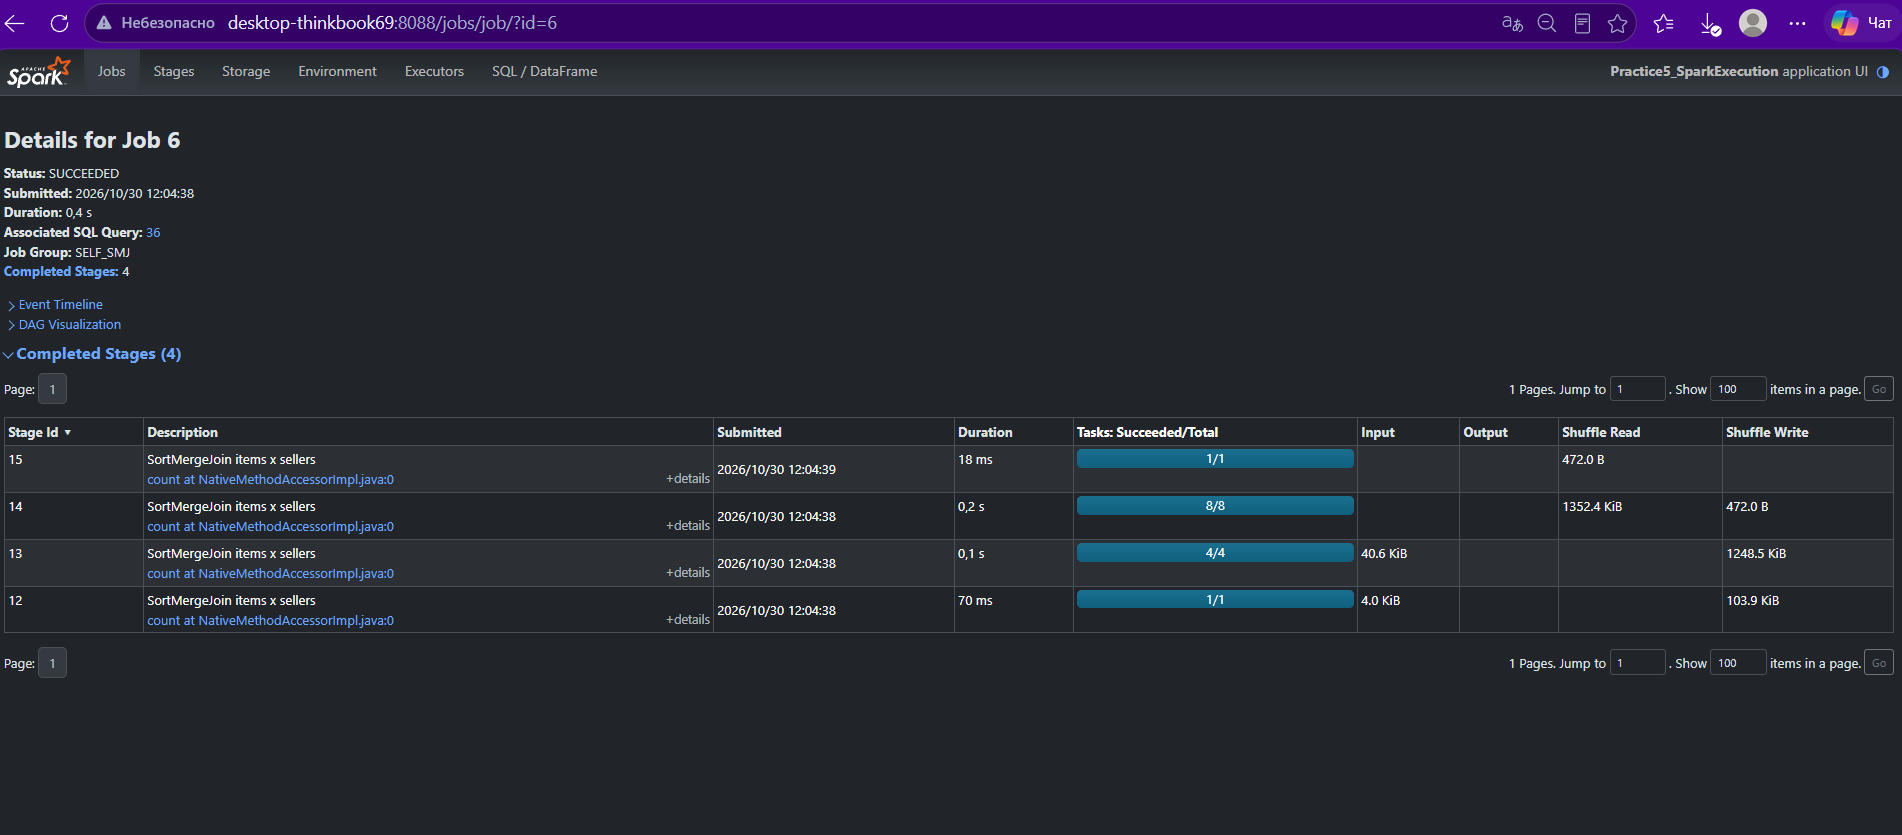

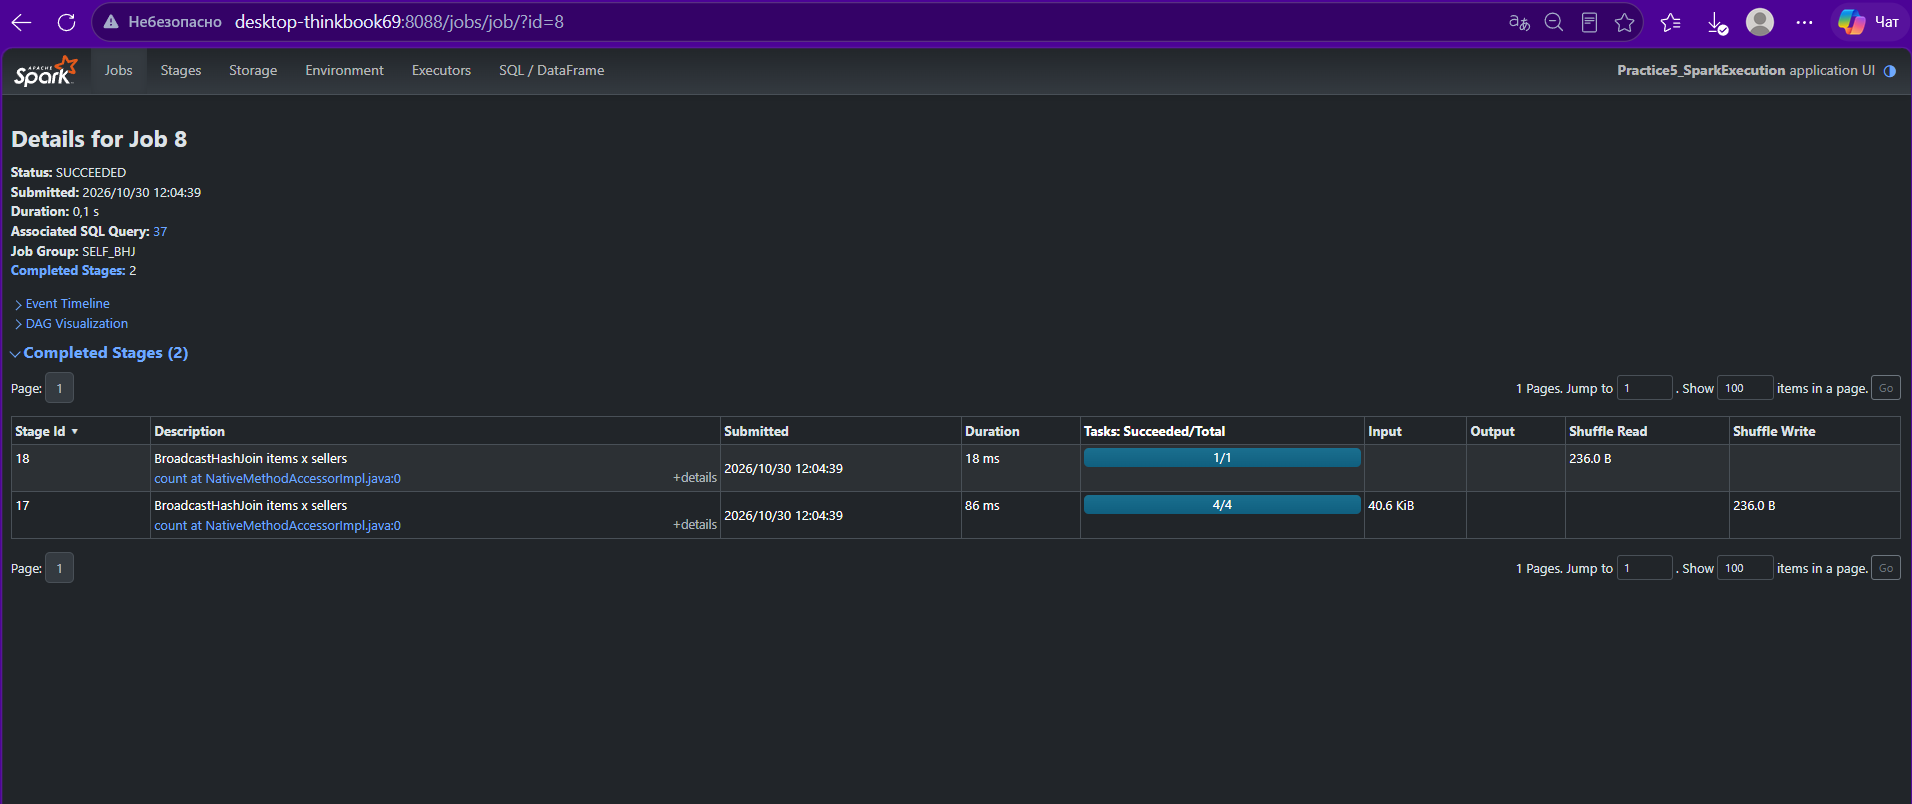

In [31]:
sc.setJobGroup("SELF_PERSIST", "Two actions: with and without cache")
spark.catalog.clearCache()

mid = (items
    .join(F.broadcast(sellers), on="seller_id", how="left")
    .withColumn("gross", F.col("price") + F.col("freight_value"))
)

def action_by_state(df):
    return (df.groupBy("seller_state")
              .agg(F.sum("gross").alias("g"))
              .agg(F.sum("g")).first()[0])

def action_by_seller(df):
    return (df.groupBy("seller_id")
              .agg(F.sum("gross").alias("g"))
              .agg(F.sum("g")).first()[0])

t0 = perf_counter()
_ = action_by_state(mid)
t1 = perf_counter()
_ = action_by_seller(mid)
t2 = perf_counter()
print(f"NO cache | action1={t1-t0:.3f}s action2={t2-t1:.3f}s | is_cached={mid.is_cached}")

cached = mid.persist(StorageLevel.MEMORY_AND_DISK)

t0 = perf_counter()
rows_cached = cached.count()
t1 = perf_counter()
_ = action_by_state(cached)
t2 = perf_counter()
_ = action_by_seller(cached)
t3 = perf_counter()
print(f"CACHED   | materialize={t1-t0:.3f}s action1={t2-t1:.3f}s action2={t3-t2:.3f}s | rows={rows_cached}")

NO cache | action1=0.414s action2=0.530s | is_cached=False
CACHED   | materialize=0.706s action1=0.388s action2=0.273s | rows=112650


Вывод по блоку 7. По отдельности кэш ускоряет агрегации: 0,485 → 0,399 с и 0,449 → 0,317 с, потому что данные берутся из памяти. Но в сумме вариант без кэша — около 0,93 с, а с кэшем — материализация 0,81 с плюс 0,72 с на агрегации, то есть около 1,53 с. Кэш не окупился: он ещё не вернул вложенные 0,8 с. Точка окупаемости — примерно четвёртое действие. Кэш оправдан только при многократном использовании промежуточного результата.

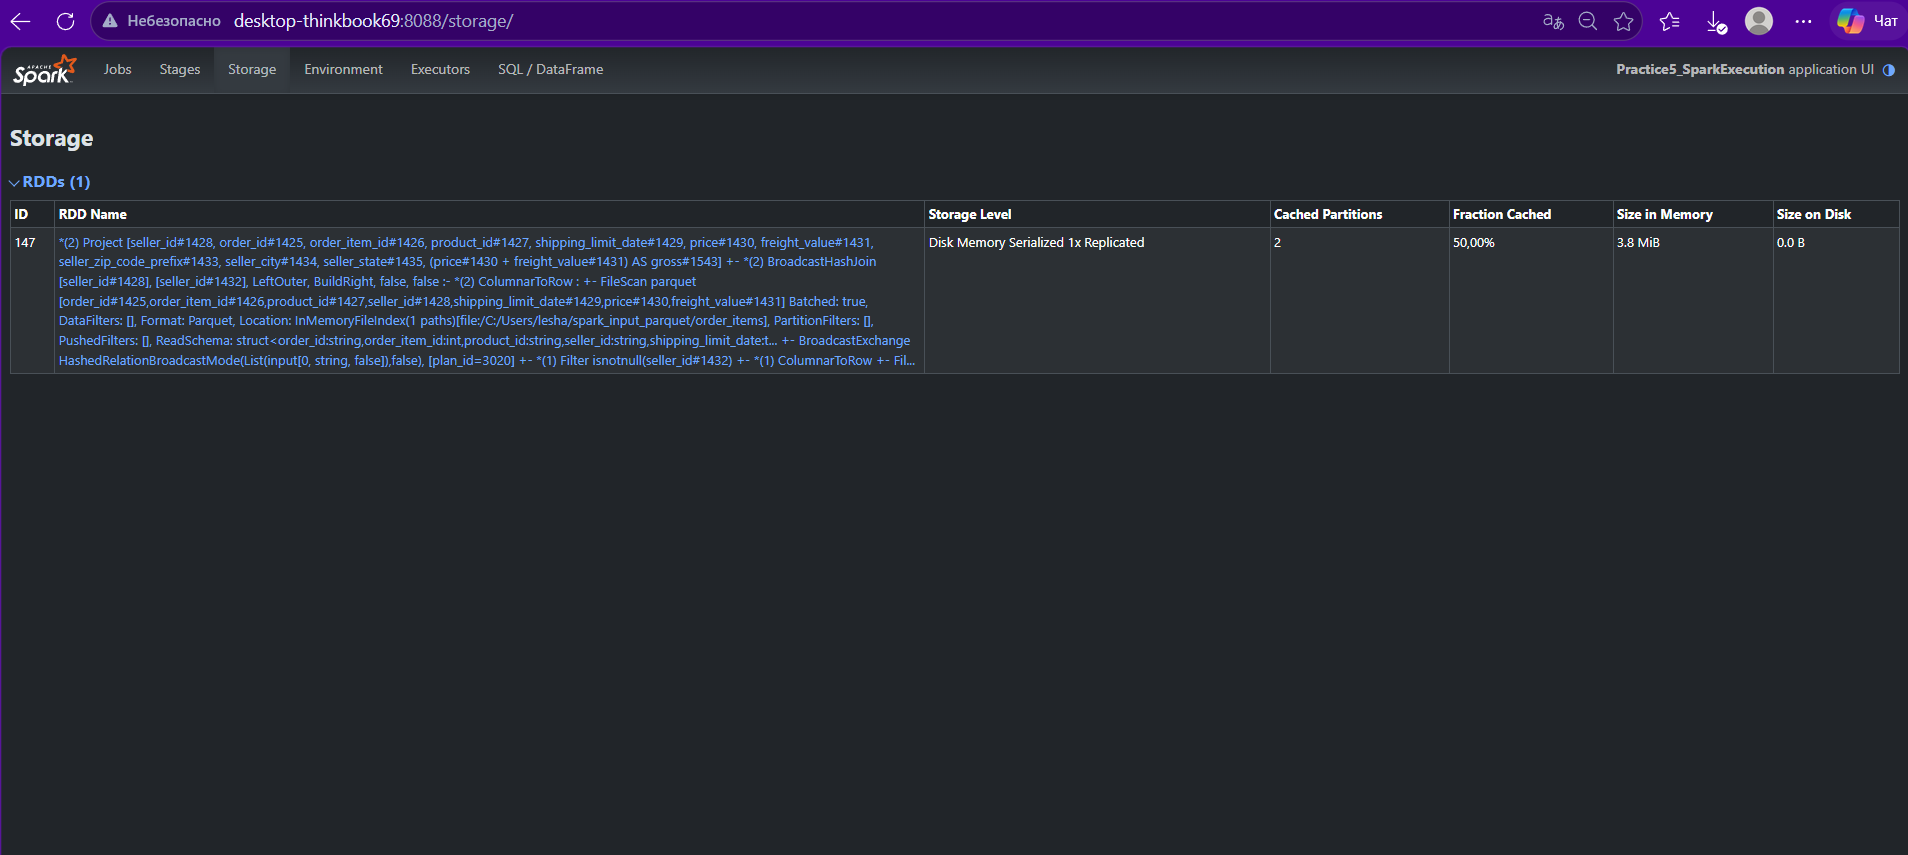

In [32]:
spark.conf.set("spark.sql.shuffle.partitions", "8")
N = 2_000_000
P_VALUES = [1, 2, 4, 8]

def run_bench(p, repeats=3):
    times, chk = [], None
    for _ in range(repeats):
        df = (spark.range(0, N, 1, numPartitions=p)
              .withColumn("key",   (F.col("id") % 1000).cast("int"))
              .withColumn("value", F.sqrt(F.col("id") + 1.0)))
        t0 = perf_counter()
        chk = (df.groupBy("key")
                 .agg(F.sum("value").alias("s"))
                 .agg(F.sum("s")).first()[0])
        times.append(perf_counter() - t0)
    return times, median(times), chk

_ = run_bench(4, repeats=1)

for p in P_VALUES:
    times, med, chk = run_bench(p, repeats=3)
    print(p, [f"{t:.3f}" for t in times], f"median={med:.3f}s  chk={chk:.4f}")

1 ['0.383', '0.107', '0.117'] median=0.117s  chk=1885618790.0631
2 ['0.303', '0.201', '0.206'] median=0.206s  chk=1885618790.0631
4 ['0.242', '0.229', '0.212'] median=0.229s  chk=1885618790.0631
8 ['0.341', '0.253', '0.255'] median=0.255s  chk=1885618790.0631


Вывод по блоку 8. Наивное «больше разделов — быстрее» не работает: один раздел оказался самым быстрым, восемь — самым медленным. Причина: после группировки Spark всё равно перемешивает данные в восемь целевых разделов, и реальный параллелизм определяется ими. Число входных разделов влияет только на первую фазу, и чем их больше, тем мельче задачи и тем больше доля времени уходит на их запуск и планирование. На двух миллионах строк эти расходы перевешивают выигрыш от параллелизма. Оптимум — не максимум, а такая величина, при которой задачи достаточно крупные.

In [33]:
OUT = Path("self_small_files")
OUT.mkdir(exist_ok=True)

def write_measure(p):
    path = OUT / f"p_{p}"
    items.repartition(p).write.mode("overwrite").parquet(str(path))
    files = list(path.glob("part-*.parquet"))
    sizes = [f.stat().st_size for f in files]
    total_mib = sum(sizes) / 1024**2
    avg_kib   = (sum(sizes) / len(sizes) / 1024) if sizes else 0
    return len(files), round(total_mib, 2), round(avg_kib, 2)

for p in [1, 4, 16]:
    n_files, total_mib, avg_kib = write_measure(p)
    print(f"p={p:>2} | files={n_files:>2} | total={total_mib:>6} MiB | avg={avg_kib:>8} KiB")

p= 1 | files= 1 | total=  6.46 MiB | avg= 6611.19 KiB
p= 4 | files= 4 | total=  7.43 MiB | avg= 1902.72 KiB
p=16 | files=16 | total=  8.73 MiB | avg=  558.86 KiB


Вывод по блоку 9. Связь прямая: один раздел — один файл, четыре — четыре, шестнадцать — шестнадцать. Общий объём растёт, средний размер падает: каждый Parquet-файл несёт собственные заголовок, схему, метаданные и статистику, а на малом объёме сжатие работает хуже. Отсюда классическая проблема маленьких файлов: тысяча файлов вместо десяти — в сто раз больше открытий и планирования при том же объёме. При записи надо ориентироваться на целевой размер файла, а не на число вычисленных разделов. Крайность в один раздел для большой таблицы тоже плоха — теряется параллелизм записи.

In [34]:
spark.stop()

### **Выводы по разделу 2**

1. Перекос по штатам огромный. На SP приходится ~71% позиций (80 342 из 112 650) и 8,75 млн из ~12,5 млн выручки. Отсюда и сохранение перекоса при coalesce: он склеивает уже неравномерные разделы, не выравнивая их.

2. Ранжирование по выручке — это ранжирование по объёму, а не по цене. У RJ и SC средняя цена выше (175 и 155), чем у SP (109), но SP лидирует по сумме в семь раз за счёт 80 тыс. позиций.

3. Справочник мал в 36 раз (3 095 продавцов на 112 650 позиций). Поэтому копирование на исполнители дешевле перемешивания факта: широковещательное соединение дало 0,233 с против 0,481 с у сортировочно-слиятельного. Будь продавцов миллионы — выигрыш исчез бы.

4. Данных мало для масштабирования по разделам. ~28 тыс. строк на раздел при 12 ядрах, а на синтетике медианы при p = 1, 2, 4, 8 растут: 0,194, 0,209, 0,226, 0,307 с. Накладные расходы на мелкие задачи перевешивают параллелизм.

5. Число файлов растёт вместе с разделами, а полезная нагрузка падает. 1 файл — 6,46 МиБ (6 611 КиБ), 4 — 7,43 МиБ (1 903 КиБ), 16 — 8,73 МиБ (559 КиБ). Общий объём вырос на треть из-за метаданных.

### **Ограничения локального стенда**

1. Датасет специфичен: много позиций, мало продавцов, один доминирующий штат. Выводы о выгодности broadcast и о сохранении перекоса опираются на это соотношение и на других данных могут не выполняться.

2. Масштаб учебный: сотня тысяч строк — доли секунды на любой вариант, разница часто в пределах шума. Реальная разница между стратегиями соединения и числом разделов проявляется на гигабайтах, поэтому найденные оптимумы нельзя переносить на промышленные задачи.